# 1. Imports

In [1]:
import numpy as np
from python.sql_module import SQL
from python.read_module import ReadData
import pandas as pd
from pathlib import Path
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns

# 2. VARIABLES

In [2]:
_CONFIG_PATH = 'config.yaml'
_READER = ReadData(_CONFIG_PATH)

# 3. DATA

In [3]:
dim_calendar = _READER.read_data(table_name='gold_sku.dim_calendar')
fact_sales_agg_daily = _READER.read_data(table_name='gold_sku.fact_sales_agg_daily')
fact_sales_agg_daily_calendar = fact_sales_agg_daily.merge(
    dim_calendar,
    on='date'
)
fact_sales_agg_daily_calendar['year'] = pd.to_datetime(fact_sales_agg_daily_calendar['date']).dt.year
fact_sales_agg_daily_calendar['year_month'] = pd.to_datetime(fact_sales_agg_daily_calendar['date']).dt.to_period('M')

# 4. DATA QUALITY CHECKS

## 4.1 fact_sales_agg_daily

In [4]:
assert fact_sales_agg_daily.shape[0] == 1826
assert int(fact_sales_agg_daily['revenue'].sum()) == 644115980

# 5. FUNCTIONS 

## 5.1 Rolling Mean Function

In [5]:
def calculate_rolling_mean(
        df: pd.DataFrame,
        rolling_window: int,
        min_occurences: int,
        agg_column: str,
        group_by_column: str = None,
) -> pd.DataFrame:
    """
    Function that calculates the moving average over the specified rolling window and column.
    Params:

            df: DataFrame for which the column should be calculated.
            rolling_window: The window for which the moving average should be calculated.
            min_occurences: Minimal number of occurences in the rollig_window for the average to be calculated.
            agg_column: Name of the column for which the average should be calculated.
            group_by_column: Name of the column of the group for which the average should be calculated.

    """
    if group_by_column:
        data_frame = pd.DataFrame(df.groupby(
            group_by_column
        )[agg_column].sum().rolling(rolling_window, min_occurences, center=True).mean()).rename(
            columns={agg_column:f'{agg_column}_{rolling_window}_d_avg'}
        )

        merged_frame = df.merge(
            data_frame,
            how='left',
            on=group_by_column
        )
        if merged_frame.columns.str.endswith('_x').any():
            return df
        else:
            return merged_frame
    else:
        raise ValueError("Please fill a group_by_column parameter.")
        
    

## 5.2 Slope and Intercept

In [6]:
def calculate_slope_and_intercept(
        df: pd.DataFrame,
        x: str,
        y: str
):
    """
    Function that calculates the slope and intercept for given parameters.
    """
    y = df[y].dropna()
    locs = y.index
    x = df[x].loc[locs]
    return np.polyfit(x,y,1)

# 6. Data Viz

# 6.1 Whole level of the shop.

In [7]:
fact_sales_agg_daily_calendar = calculate_rolling_mean(fact_sales_agg_daily_calendar, 7, 7, 'revenue', group_by_column='date')
fact_sales_agg_daily_calendar = calculate_rolling_mean(fact_sales_agg_daily_calendar, 30, 30, 'revenue', group_by_column='date')

In [8]:
slope_reg, intercept_reg = calculate_slope_and_intercept(
    fact_sales_agg_daily_calendar,
    x = 'days_since_start',
    y = 'revenue'
)

In [9]:
regular_line = slope_reg * fact_sales_agg_daily_calendar['days_since_start'] + intercept_reg

### 6.1.1 Daily Level.

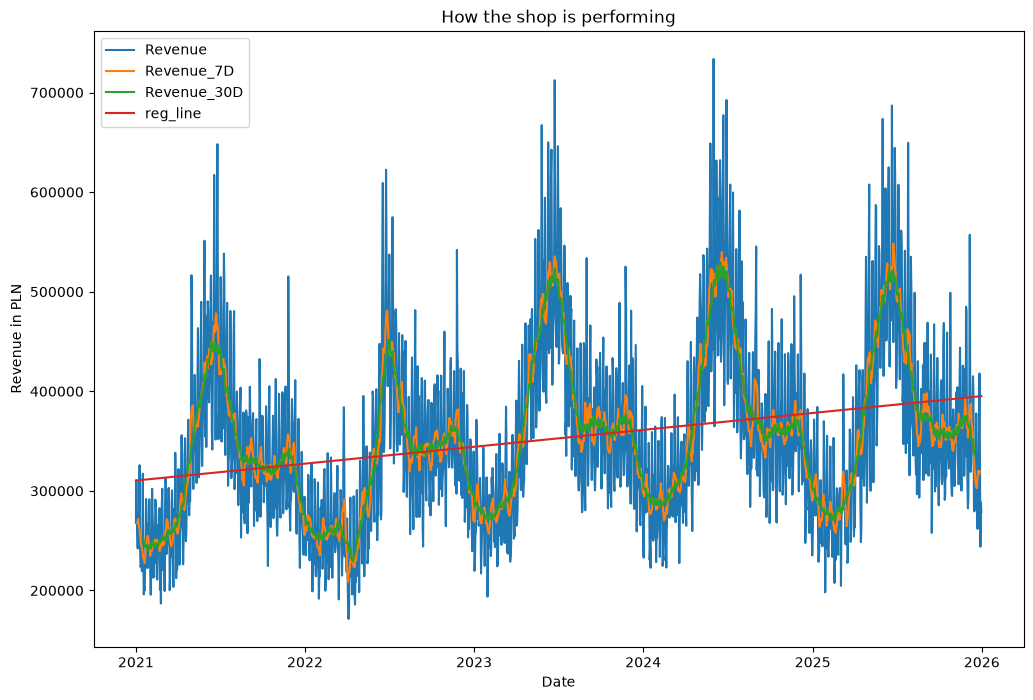

In [10]:
plt.figure(figsize=(12,8))
sns.lineplot(fact_sales_agg_daily_calendar, x='date', y='revenue', label = 'Revenue')
sns.lineplot(fact_sales_agg_daily_calendar, x='date', y = 'revenue_7_d_avg', label = 'Revenue_7D')
sns.lineplot(fact_sales_agg_daily_calendar, x='date', y = 'revenue_30_d_avg', label = 'Revenue_30D')
plt.plot(fact_sales_agg_daily_calendar['date'], regular_line, label = 'reg_line')
plt.legend();
plt.ylabel("Revenue in PLN");
plt.xlabel("Date");
plt.title("How the shop is performing");

In the overall we can see the overall rising trend in the revenue. The sales are at the lowest at the first months of the particular years, and at the highest level at the middle of the year. At the beggining of the 2022 the sales were at the lowest, after the usual drop, sales went down even more. The rest of the years look almost the same.

### 6.1.2 Yearly Level

Text(0.5, 0, 'Year')

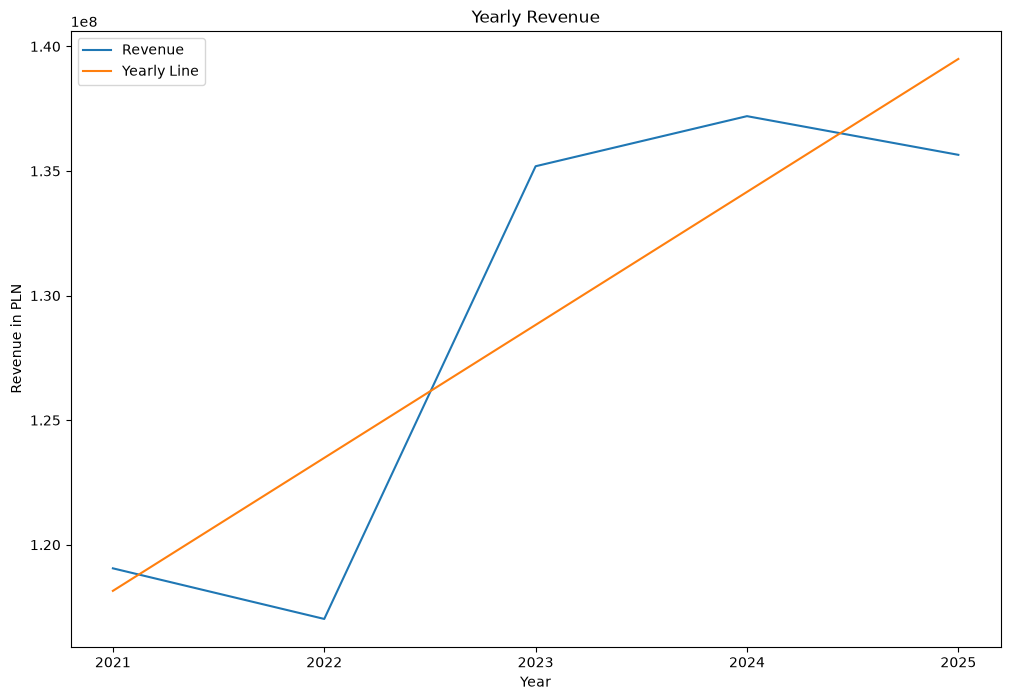

In [11]:
yearly_lvl = fact_sales_agg_daily_calendar.groupby(
    'year'
)['revenue'].sum().reset_index()

yearly_lvl['_len'] = np.arange(len(yearly_lvl))
yearly_slope, yearly_intercept = calculate_slope_and_intercept(
    yearly_lvl,
    x='_len',
    y = 'revenue'
)

yearly_line = yearly_slope * yearly_lvl['_len'] + yearly_intercept

plt.figure(figsize=(12,8))
ax = sns.lineplot(yearly_lvl, x='year', y='revenue', label = "Revenue")
plt.plot(yearly_lvl['year'], yearly_line, label="Yearly Line")
ax.set_xticks(np.array([2021, 2022 ,2023 ,2024, 2025]));
plt.legend();
plt.title("Yearly Revenue");
plt.ylabel("Revenue in PLN");
plt.xlabel("Year")

Just as I mentioned before - in general we can see a growing trend. Sales were at the lowest at 2022 but rapidly exploded at 2023. Then the trend slowed down, at 2024, to change its direction at 2025 which was the first year in several years to have a lower sales than the priovious one.

#### 6.1.2.1 Y/Y Level

Text(0, 0.5, 'Revenue')

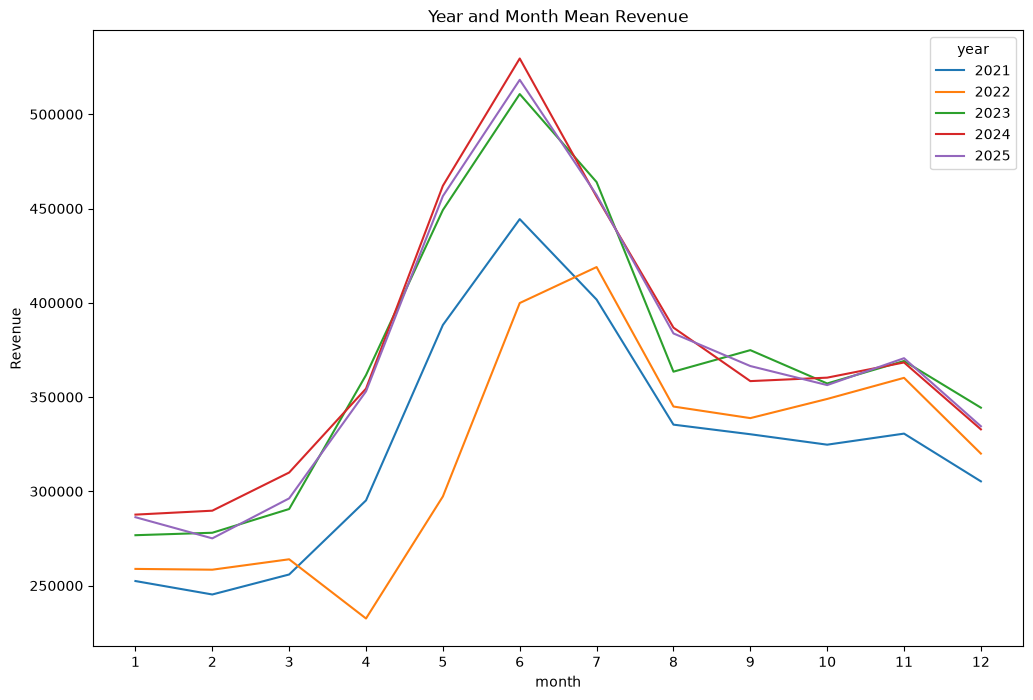

In [12]:
base = fact_sales_agg_daily_calendar.groupby(
    ['year','month']
)['revenue'].mean().reset_index()

base['year'] = base['year'].astype(str)

plt.figure(figsize=(12,8))
ax = sns.lineplot(base, x='month', y='revenue', hue='year');
ax.set_xticks(np.arange(1,13));
plt.title("Year and Month Mean Revenue");
plt.ylabel("Revenue")

For most of the years, the lowest point of sales was in February - and as we mentioned before April in 2022 was an unexpected anomaly. For most of the years, the higest sum of sales was in June - the only exception is year 2022 where the peak was shifted do July.

## 6.1.3 Monthly Level

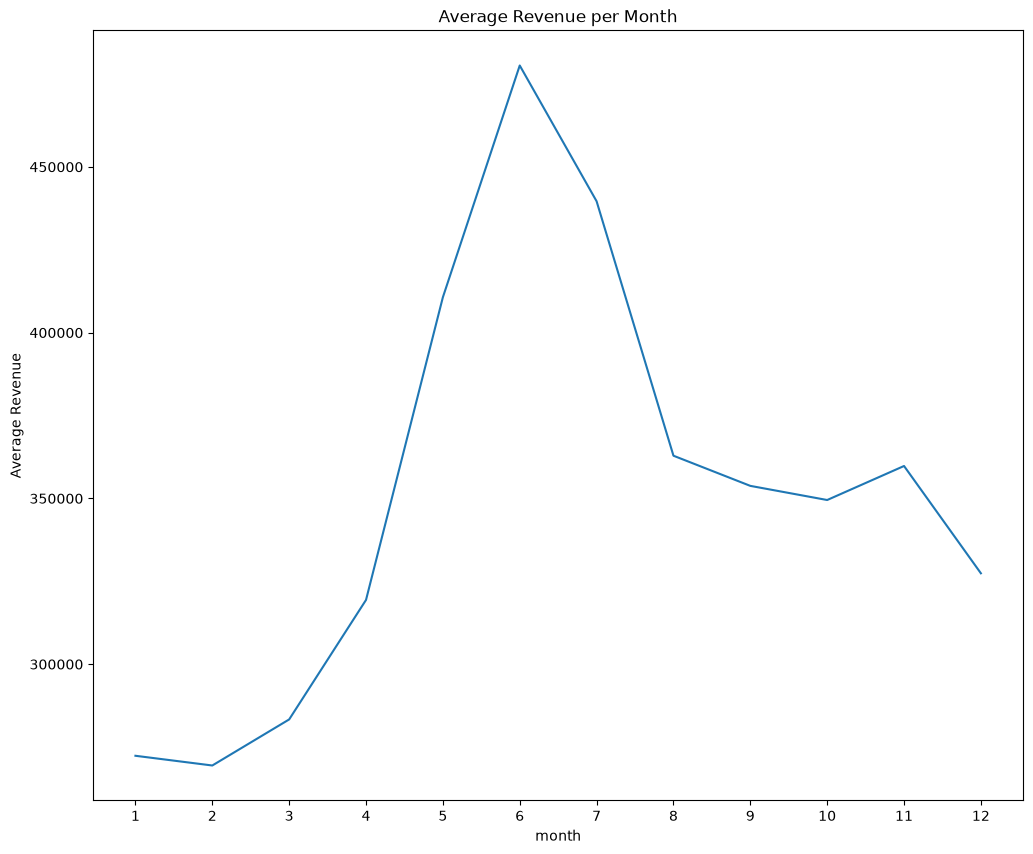

In [13]:
month_lvl = fact_sales_agg_daily_calendar.groupby(
    ['month']
)['revenue'].mean().reset_index()

plt.figure(figsize=(12,10))
ax = sns.lineplot(month_lvl, x ="month", y = "revenue")
ax.set_xticks(np.arange(1,13))
plt.title("Average Revenue per Month");
plt.ylabel("Average Revenue");

It's almost the same as we saw before. The lowest point is in Fabruary, and the highest point is June. We can also see that at the October, our sales are changing their trend, just to go down in december.

## 6.1.4 Weekly Level

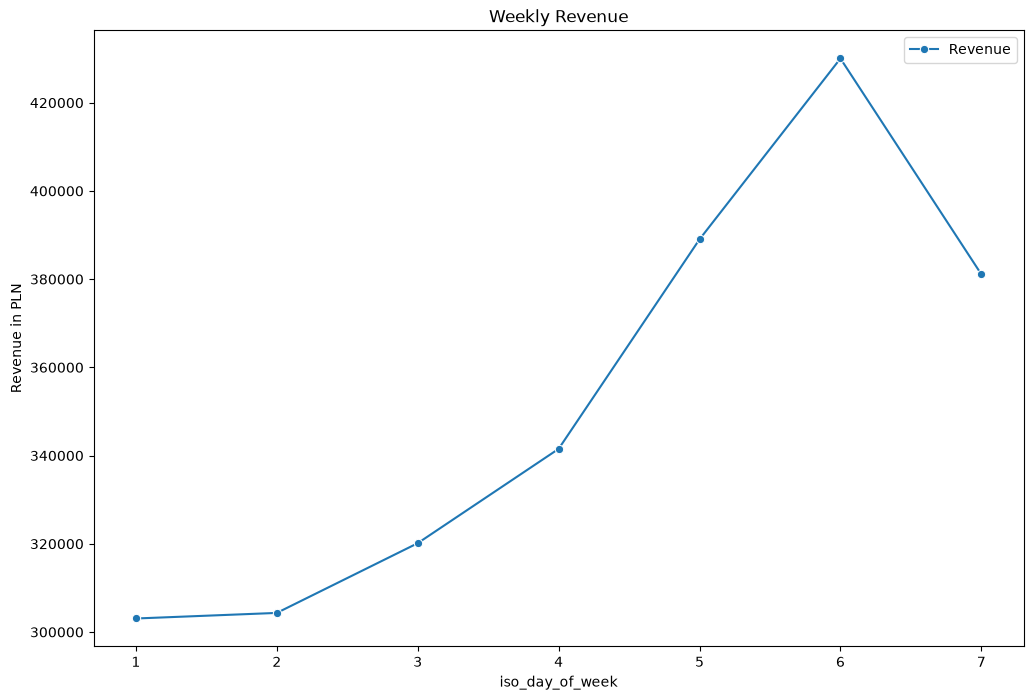

In [14]:
week_lvl = fact_sales_agg_daily_calendar.groupby(
    'iso_day_of_week'
)['revenue'].mean().reset_index()


plt.figure(figsize=(12,8))
ax = sns.lineplot(week_lvl, x='iso_day_of_week', y='revenue', label = "Revenue", marker='o')
plt.legend();
plt.title("Weekly Revenue");
plt.ylabel("Revenue in PLN");


We have the highest amount of sales at the weekend, where Saturday is the king. Our sales are beggining to rise at the wednesday, and keep on rising up until Saturday.